# Mean–Variance Portfolio Theory

Which combination of investments offers the most expected return for its risk? Mean–variance analysis connects that portfolio question to asset pricing. Under CAPM's assumptions, the market is the tangency portfolio: no other combination offers a higher expected excess return per unit of volatility.

A strategy with nonzero population alpha challenges that proposition. After hedging its market exposure, it leaves an expected payoff outside the market benchmark. Under unrestricted trading and nonsingular covariance, combining that payoff with the market expands the investment opportunity set and increases the maximum attainable Sharpe ratio.

We develop this geometry through portfolio return and risk, the efficient frontier, and the tangency portfolio. We then use the supplied factor returns to compare the MKT–SMB–HML subset with all five factors, showing how their estimated frontiers, tangency combinations, and exposures differ. The application describes historical opportunities estimated in sample, rather than future returns an investor is assured of earning.

In [6]:
import sys
from pathlib import Path
ROOT=Path.cwd().resolve()
ROOT=ROOT.parent if ROOT.name=='notebooks' else ROOT
sys.path.insert(0,str(ROOT/'src'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
NAVY, BLUE, GREEN, ORANGE, GRAY = '#17324D', '#2878A5', '#168A86', '#D99A32', '#737D87'
STYLE={'font.family':'DejaVu Sans','font.size':11,'axes.titlesize':12,'axes.labelsize':11,
       'xtick.labelsize':10,'ytick.labelsize':10,'legend.fontsize':10,'figure.dpi':110,
       'figure.facecolor':'white','axes.facecolor':'white','axes.spines.top':False,
       'axes.spines.right':False,'axes.prop_cycle':plt.cycler(color=[BLUE,GREEN,ORANGE,NAVY]),
       'grid.alpha':.15,'lines.linewidth':1.8}
plt.rcParams.update(STYLE)
from factor_asset_pricing.mean_variance import global_minimum_variance, tangency_portfolio, efficient_frontier, portfolio_statistics
from factor_asset_pricing.asset_pricing_tests import maximum_sharpe_ratio
from factor_asset_pricing.french_data import load_french, sample_coverage
RAW = ROOT / "data/raw/french"


## 1. Mean–variance portfolio theory

### 1.1 Portfolio return, risk, and diversification

An investor holds a combination of investments, rather than an isolated return series. An investment's contribution therefore depends on both its expected return and the way it fluctuates with the rest of the portfolio. A modest standalone Sharpe ratio does not rule out a useful contribution through diversification.

For a vector of returns $\mathbf R_t$, let $\boldsymbol\mu=E[\mathbf R_t]$ and $\Sigma=\operatorname{Var}(\mathbf R_t)$. A combination with weights $\mathbf w$ has

$$\mu_p=\mathbf w'\boldsymbol\mu,\qquad\sigma_p^2=\mathbf w'\Sigma\mathbf w.$$

Expected return is linear in the positions. Variance includes their pairwise covariances. For two investments,

$$\sigma_p^2=w_1^2\sigma_1^2+w_2^2\sigma_2^2+2w_1w_2\operatorname{Cov}(R_1,R_2).$$

For positive positions, lower covariance reduces combined variance without changing either investment's standalone volatility. Negative positions can hedge common fluctuations. Their use also changes leverage and implementation requirements.

For ordinary fully invested risky assets, $\mathbf1'\mathbf w=1$ is a capital-budget constraint. For constructed long–short factor payoffs, the same moment formulas apply to exposure notionals, but a unit-sum condition is a chosen normalization rather than an intrinsic capital budget. We distinguish these interpretations in the example.

### 1.2 The efficient frontier

Mean–variance optimization asks which combination has the lowest variance for a chosen expected return. With unrestricted signed weights and a unit-sum constraint, the problem is

$$\min_{\mathbf w}\ \mathbf w'\Sigma\mathbf w
\quad\text{subject to}\quad\mathbf1'\mathbf w=1,\quad\mathbf w'\boldsymbol\mu=\mu^*.$$

For positive-definite $\Sigma$, define the following quantities to express the solution:

$$A=\mathbf1'\Sigma^{-1}\mathbf1,\quad B=\mathbf1'\Sigma^{-1}\boldsymbol\mu,\quad C=\boldsymbol\mu'\Sigma^{-1}\boldsymbol\mu,\quad D=AC-B^2>0.$$

Solving the budget and mean constraints yields the general minimum-variance allocation and its variance:

$$\mathbf w(\mu^*)=\Sigma^{-1}\left[\frac{C-B\mu^*}{D}\mathbf1+\frac{A\mu^*-B}{D}\boldsymbol\mu\right],$$

$$\sigma^2(\mu^*)=\frac{A(\mu^*)^2-2B\mu^*+C}{D}.$$

Varying $\mu^*$ traces the minimum-variance boundary. Its upper branch is the efficient frontier: below that branch, another allocation can deliver a higher mean at the same volatility. The condition $D>0$ rules out a redundant target-mean constraint.

Without the target-return constraint, the global minimum-variance allocation is

$$\mathbf w_{GMV}=\frac{\Sigma^{-1}\mathbf1}{A},\qquad\mu_{GMV}=\frac BA,\qquad\sigma_{GMV}^2=\frac1A.$$

GMV is the leftmost point of the boundary. It minimizes variance, rather than maximizing expected return or Sharpe ratio. The upper branch begins at its mean $B/A$. These formulas allow negative positions, so their frontier generally differs from one constrained to long-only allocations.

### 1.3 The tangency portfolio

A risk-free asset lets the investor separate the choice of risky combination from its scale. For ordinary risky total returns, $\boldsymbol\mu$ is the vector of expected returns, $r_f$ is the risk-free return for the same period, and $\mathbf1$ is a vector of ones. Expected excess returns are therefore $\boldsymbol\mu-r_f\mathbf1$. The Sharpe ratio is

$$SR(\mathbf w)=\frac{\mathbf w'(\boldsymbol\mu-r_f\mathbf1)}{\sqrt{\mathbf w'\Sigma\mathbf w}}.$$

Lending or borrowing against a risky combination traces a capital allocation line. In total-return space it begins at $(0,r_f)$, and its slope is the combination's Sharpe ratio. The steepest attainable positive line touches the efficient risky frontier at the tangency portfolio.

The tangency weights are covariance-adjusted expected excess returns, normalized to sum to one:

$$\mathbf w_T=\frac{\Sigma^{-1}(\boldsymbol\mu-r_f\mathbf1)}{\mathbf1'\Sigma^{-1}(\boldsymbol\mu-r_f\mathbf1)},\qquad SR_{\max}^2=(\boldsymbol\mu-r_f\mathbf1)'\Sigma^{-1}(\boldsymbol\mu-r_f\mathbf1).$$

The unit-sum expression requires $\mathbf1'\Sigma^{-1}(\boldsymbol\mu-r_f\mathbf1)>0$ to preserve the positive maximum-Sharpe orientation. If the sum is zero, it cannot be used. If it is negative, dividing by it reverses the payoff's direction. A positive exposure normalization, such as unit gross exposure, preserves the maximizing direction in those cases. Position scale changes expected excess payoff and volatility proportionally, leaving Sharpe unchanged.

For traded factors, $\mathbf F_t$ already contains excess-return payoffs. In the formulas above, use their expected payoffs $E[\mathbf F_t]$ directly in place of $\boldsymbol\mu-r_f\mathbf1$. We do not subtract RF again. Their maximum-Sharpe lines start at the origin in excess-payoff space. Multiplying factor positions by a positive number describes increased exposure, not a change in the underlying combination.

Under CAPM's equilibrium assumptions, the theoretical all-wealth market is the tangency portfolio. An observed equity-market factor is a proxy. As explained in 04, nonzero population alpha after benchmark hedging supplies an additional mean payoff uncorrelated with the benchmark factors, increasing their unrestricted maximum Sharpe ratio. Alpha against MKT alone does not establish incremental value beyond a multifactor benchmark.

Adding investments cannot worsen an unrestricted optimum when the original positions remain feasible. A strict population improvement requires incremental expected compensation after benchmark exposure is removed. A historical improvement computed from estimated moments is not proof that the population improvement exists or will persist.

## 2. Example: from three-factor to five-factor investment opportunities

### 2.1 Factor returns and the exposure convention

We use published FF5 returns from the [Kenneth French Data Library](https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/data_library.html) on the same complete-case factor sample as 04: July 1963 through December 2024, totaling 738 consecutive months. MKT is the market-only benchmark. The three-factor subset contains MKT, SMB, and HML, while FF5 additionally contains RMW and CMA.

The supplied SMB follows the five-factor construction explained in 03. The three-factor subset is therefore a nested benchmark using that SMB, rather than an exact reconstruction of conventional FF3. All inputs are already excess-return payoffs. Sample means are arithmetic monthly averages, and covariance uses divisor $T-1$.

For the curved frontiers, we impose $\mathbf1'\mathbf w=1$ on signed factor exposures. This defines comparable unit-sum exposure combinations for both investment sets. It does not assert that a dollar-neutral factor requires one dollar of net investment, or that these exposures form an ordinary fully invested risky portfolio. GMV refers to minimum variance under this specific normalization. Without a scale constraint, zero exposure would trivially minimize factor-payoff variance.

The maximum-Sharpe direction does not depend on positive scaling. We show its unrestricted allocation line as well as its unit-sum tangency point, provided the normalization preserves its orientation. Both investment sets satisfy that condition in this sample.

In [7]:
factors = load_french("ff5", RAW).loc["1963-07":"2024-12"]
assert len(factors) == 738 and not factors.isna().any().any()
factor_panel=factors[["MKT","SMB","HML","RMW","CMA"]]
print(f"Common monthly sample: {factor_panel.index.min():%B %Y}–{factor_panel.index.max():%B %Y}, T = {len(factor_panel)}")
inputs=pd.DataFrame({"Mean (% monthly)":factor_panel.mean()*100,
                     "Volatility (% monthly)":factor_panel.std(ddof=1)*100,
                     "Monthly Sharpe":factor_panel.mean()/factor_panel.std(ddof=1)})
display(inputs)
correlations=factor_panel.corr()
correlations.index.name="Factor correlations"
display(correlations)
display(sample_coverage(factor_panel))


Common monthly sample: July 1963–December 2024, T = 738


,Mean (% monthly),Volatility (% monthly),Monthly Sharpe
MKT,0.586748,4.476018,0.131087
SMB,0.193740,3.037376,0.063785
HML,0.281247,2.971534,0.094647
RMW,0.284255,2.216968,0.128218
CMA,0.249336,2.057646,0.121175


,MKT,SMB,HML,RMW,CMA
Factor correlations,,,,,
MKT,1.000000,0.276369,-0.203698,-0.186416,-0.358358
SMB,0.276369,1.000000,0.009497,-0.350410,-0.087529
HML,-0.203698,0.009497,1.000000,0.082156,0.685937
RMW,-0.186416,-0.350410,0.082156,1.000000,-0.009411
CMA,-0.358358,-0.087529,0.685937,-0.009411,1.000000


,start,end,observations,missing
MKT,1963-07-01 00:00:00,2024-12-01 00:00:00,738,0
SMB,1963-07-01 00:00:00,2024-12-01 00:00:00,738,0
HML,1963-07-01 00:00:00,2024-12-01 00:00:00,738,0
RMW,1963-07-01 00:00:00,2024-12-01 00:00:00,738,0
CMA,1963-07-01 00:00:00,2024-12-01 00:00:00,738,0


Standalone means and volatilities do not determine the best combination. The correlation table shows why: HML and CMA are positively correlated at approximately 0.69, while SMB and RMW have a correlation of approximately −0.35. Several characteristic factors also have negative correlations with MKT. Their contributions depend on these joint relationships, not only on their individual Sharpe ratios.

### 2.2 Estimated frontiers and tangency portfolios

We apply the public frontier, GMV, and tangency APIs to the same sample moments. For the already-excess factor payoffs, the zero intercept of the allocation lines represents zero excess payoff, not a second risk-free deduction. Solid curved lines show efficient branches and faint dashed curves show dominated branches.

The two investment sets are nested. An existing three-factor allocation remains feasible in FF5 by setting RMW and CMA exposures to zero. Thus the added factors cannot increase the minimum variance at any shared target mean under the same unit-sum constraint.

In [8]:
sets={"Three-factor subset":["MKT","SMB","HML"],"FF5":["MKT","SMB","HML","RMW","CMA"]}
allocations={}
performance_rows={}
weight_columns={}
for name,columns in sets.items():
    returns=factor_panel[columns]
    mean=returns.mean().to_numpy()
    covariance=returns.cov().to_numpy()
    gmv=global_minimum_variance(covariance)
    tangency=tangency_portfolio(mean,covariance,risk_free_rate=0)
    stats={kind:portfolio_statistics(w,mean,covariance,risk_free_rate=0)
           for kind,w in [("GMV",gmv),("Tangency",tangency)]}
    allocations[name]={"columns":columns,"mean":mean,"covariance":covariance,
                       "GMV":gmv,"Tangency":tangency,"statistics":stats}
    for kind,w in [("GMV",gmv),("Tangency",tangency)]:
        label=f"{name}: {kind}"
        s=stats[kind]
        performance_rows[label]={"Mean (% monthly)":s["expected_return"]*100,
                                 "Volatility (% monthly)":s["volatility"]*100,
                                 "Monthly Sharpe":s["sharpe"]}
        weight_columns[label]=pd.Series(w,index=columns).reindex(factor_panel.columns,fill_value=0)
market_stats=portfolio_statistics([1],factor_panel[["MKT"]].mean(),factor_panel[["MKT"]].cov(),risk_free_rate=0)
performance_rows={"MKT only":{"Mean (% monthly)":market_stats["expected_return"]*100,
                              "Volatility (% monthly)":market_stats["volatility"]*100,
                              "Monthly Sharpe":market_stats["sharpe"]},**performance_rows}
performance=pd.DataFrame(performance_rows).T
weights=pd.DataFrame(weight_columns)
targets=np.linspace(0,.009,241)
for name,a in allocations.items():
    a["frontier"]=efficient_frontier(a["mean"],a["covariance"],target_returns=targets)

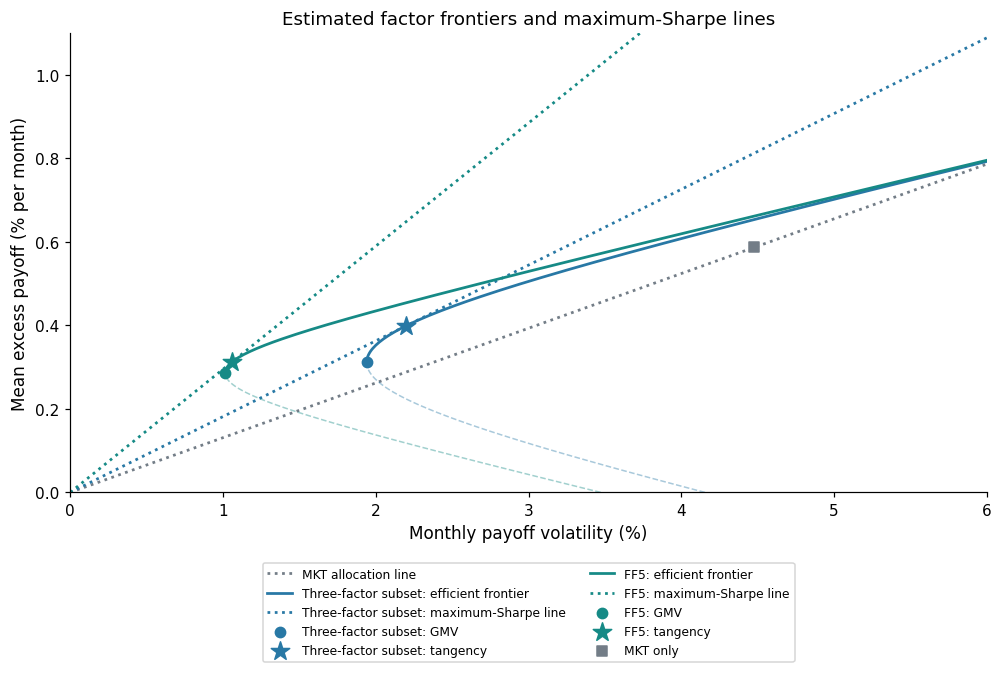

In [9]:
fig,ax=plt.subplots(figsize=(9,6),layout="constrained")
colors={"Three-factor subset":BLUE,"FF5":GREEN}
volatility_grid=np.linspace(0,.06,200)
ax.plot(volatility_grid*100,volatility_grid*market_stats["sharpe"]*100,color=GRAY,ls=":",label="MKT allocation line")
for name,a in allocations.items():
    color=colors[name]
    frontier=a["frontier"]
    gmv=a["statistics"]["GMV"]
    tangent=a["statistics"]["Tangency"]
    upper=frontier["expected_return"]>=gmv["expected_return"]
    ax.plot(frontier.loc[upper,"volatility"]*100,frontier.loc[upper,"expected_return"]*100,color=color,label=f"{name}: efficient frontier")
    ax.plot(frontier.loc[~upper,"volatility"]*100,frontier.loc[~upper,"expected_return"]*100,color=color,ls="--",alpha=.4,lw=1)
    ax.plot(volatility_grid*100,volatility_grid*tangent["sharpe"]*100,color=color,ls=":",label=f"{name}: maximum-Sharpe line")
    ax.scatter(gmv["volatility"]*100,gmv["expected_return"]*100,color=color,marker="o",s=45,zorder=4,label=f"{name}: GMV")
    ax.scatter(tangent["volatility"]*100,tangent["expected_return"]*100,color=color,marker="*",s=160,zorder=5,label=f"{name}: tangency")
ax.scatter(market_stats["volatility"]*100,market_stats["expected_return"]*100,color=GRAY,marker="s",s=50,zorder=4,label="MKT only")
ax.set(xlim=(0,6),ylim=(0,1.1),xlabel="Monthly payoff volatility (%)",ylabel="Mean excess payoff (% per month)",title="Estimated factor frontiers and maximum-Sharpe lines")
ax.legend(fontsize=8,ncol=2,loc="upper center",bbox_to_anchor=(.5,-.14))
plt.show()

The FF5 efficient frontier lies to the left of the three-factor frontier at a shared target mean, indicating less estimated variance for that mean under the stated constraint. Its maximum-Sharpe line is also steeper. GMV and tangency answer different questions, although the FF5 points lie close together in this sample.

The market-only monthly Sharpe ratio is approximately 0.131. The maximum is approximately 0.182 for the three-factor subset and 0.295 for FF5. These are in-sample estimates from identical dates. They show that the additional factors improve the estimated combinations, without proving that the population market or three-factor benchmark is inefficient. The CAPM-spanning results in 04 use MKT alone and do not test the incremental role of RMW and CMA against the three-factor subset.

### 2.3 Exposures and the resulting portfolios

The tables connect each point on the figure to its actual factor positions and payoff moments. Exposures sum to one in every displayed combination, but can be negative. A coefficient of 0.4 scales the reported factor payoff by 0.4. It does not mean that 40% of net cash wealth has been invested in a dollar-neutral factor. Underlying long and short positions, financing, collateral, and gross exposure require a separate implementation analysis.

,Three-factor subset: GMV,Three-factor subset: Tangency,FF5: GMV,FF5: Tangency
Factor exposure,,,,
MKT,0.192171,0.407387,0.110380,0.177085
SMB,0.325493,0.083282,0.182921,0.115658
HML,0.482336,0.509331,-0.079562,-0.052799
RMW,0.000000,0.000000,0.351230,0.339595
CMA,0.000000,0.000000,0.435031,0.420462


,Mean (% monthly),Volatility (% monthly),Monthly Sharpe
MKT only,0.586748,4.476018,0.131087
Three-factor subset: GMV,0.311472,1.940691,0.160496
Three-factor subset: Tangency,0.398416,2.194903,0.181519
FF5: GMV,0.286135,1.014269,0.282110
FF5: Tangency,0.312830,1.060526,0.294976


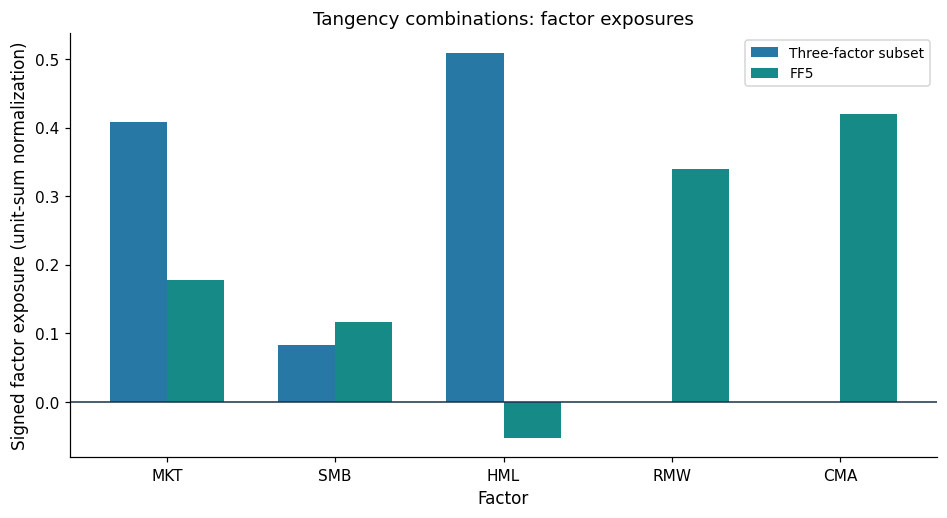

In [10]:
weights.index.name="Factor exposure"
display(weights)
display(performance)
fig,ax=plt.subplots(figsize=(8.5,4.6),layout="constrained")
positions=np.arange(len(factor_panel.columns))
width=.34
for offset,(name,color) in enumerate(colors.items()):
    column=f"{name}: Tangency"
    ax.bar(positions+(offset-.5)*width,weights[column],width=width,color=color,label=name)
ax.axhline(0,color=NAVY,lw=1)
ax.set(xticks=positions,xticklabels=factor_panel.columns,xlabel="Factor",ylabel="Signed factor exposure (unit-sum normalization)",title="Tangency combinations: factor exposures")
ax.legend(fontsize=9)
plt.show()

The three-factor tangency combination assigns approximately 40.7% exposure to MKT, 8.3% to SMB, and 50.9% to HML. The FF5 combination instead assigns approximately 17.7% to MKT, 11.6% to SMB, −5.3% to HML, 34.0% to RMW, and 42.0% to CMA.

The negative HML coefficient reverses that factor's long and short legs. It is a covariance-adjusted hedge within the estimated combination, rather than a conclusion that value investing has a negative expected return. Its role must be read alongside the positive HML–CMA correlation and the other exposures. The FF5 signed exposures sum to one, while their absolute values sum to approximately 1.11. That gross factor-exposure measure is not the same as the underlying securities' gross exposure.

At the chosen normalization, FF5 tangency has an estimated mean excess payoff of approximately 0.313% per month and volatility of 1.061%. Three-factor tangency has a higher mean, approximately 0.398%, but volatility of 2.195%. The larger FF5 Sharpe ratio comes from the combination of mean and covariance, not a higher mean alone. Positive rescaling could place either combination at another volatility without changing its Sharpe ratio.

### 2.4 What the estimated expansion establishes

The example translates the investment meaning of alpha into portfolio geometry. Adding RMW and CMA preserves the original feasible allocations and, in this sample, supplies combinations with lower variance at a target payoff and higher maximum Sharpe. The displayed exposures identify the combinations behind that improvement.

All means, covariances, and positions are estimated using the full historical sample. Selecting the combination with the best Sharpe on that same history makes the reported optimum optimistic as an assessment of future performance. Small changes in mean estimates or covariance can also materially change exposures, especially when large offsetting positions are permitted.

The calculations impose no transaction costs, short-sale restrictions, financing limits, or collateral requirements. They describe estimated payoff opportunities under idealized trading assumptions, rather than an implemented strategy. Out-of-sample evidence would be needed to evaluate whether an investor could realize the improvement.

CAPM's market-efficiency claim and the empirical factor combination thus remain distinct. Notebook 07 evaluates joint alpha restrictions for test portfolios and relates that evidence to mean–variance efficiency under the relevant assumptions.

## References

- Kenneth R. French Data Library. [Factor and portfolio data](https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/data_library.html).
